<a href="https://colab.research.google.com/github/radengustirangga-hub/Tugas_Klasifikasi_data/blob/main/Tugas_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Individu: Studi Kasus Klasifikasi
## Klasifikasi Tumor Payudara (Jinak vs Ganas) Menggunakan Machine Learning

**Nama:** Raden Gusti Rangga  
**NIM:** 2404010013  
**Mata Kuliah:** Data Mining

## 1. Latar Belakang dan Permasalahan

Kanker payudara merupakan salah satu jenis kanker yang paling sering dialami perempuan di dunia. Peluang kesembuhan sangat bergantung pada seberapa dini tumor terdeteksi dan seberapa tepat tumor tersebut dibedakan antara **jinak (benign)** dan **ganas (malignant)**.

Salah satu prosedur diagnosis adalah *Fine Needle Aspirate* (FNA), yaitu pengambilan sampel sel dari benjolan dengan jarum halus. Sampel tersebut difoto secara digital, lalu ciri-ciri inti sel (ukuran, bentuk, tekstur, dll.) diukur. Interpretasi manual dari ciri-ciri ini membutuhkan keahlian dokter/patolog dan dapat memakan waktu serta bersifat subjektif.

**Permasalahan:** bagaimana membangun model *machine learning* yang dapat mengklasifikasikan suatu tumor sebagai *jinak* atau *ganas* secara otomatis berdasarkan ciri-ciri inti sel hasil FNA?

Ini adalah masalah **klasifikasi biner** (dua kelas), karena target yang diprediksi berupa kategori: `malignant` (ganas) atau `benign` (jinak).

## 2. Dataset

Dataset yang digunakan adalah **Breast Cancer Wisconsin (Diagnostic) Dataset (WDBC)** dari *UCI Machine Learning Repository*, yang disumbangkan pada tahun 1995 oleh Wolberg, Street, dan Mangasarian dari University of Wisconsin.

| Aspek | Keterangan |
|---|---|
| Sumber | UCI Machine Learning Repository (juga tersedia di `scikit-learn`) |
| Jumlah data | 569 sampel pasien |
| Jumlah fitur | 30 fitur numerik |
| Target | `malignant` (ganas) atau `benign` (jinak) |
| Asal fitur | Citra digital FNA massa payudara, dihitung dari karakteristik inti sel |

Ada **10 karakteristik dasar** inti sel (radius, tekstur, perimeter, area, kehalusan/*smoothness*, kekompakan/*compactness*, kecekungan/*concavity*, titik cekung/*concave points*, simetri, dan dimensi fraktal). Untuk tiap karakteristik dihitung tiga nilai: **mean**, **standard error**, dan **worst** (nilai terbesar), sehingga totalnya 10 × 3 = 30 fitur.

## 3. Metode Klasifikasi yang Digunakan

Pada studi kasus ini dibandingkan **lima algoritma klasifikasi**, lalu dipilih yang terbaik:

| Algoritma | Ide singkat |
|---|---|
| **Logistic Regression** | Model linear yang menghitung probabilitas suatu data masuk ke kelas tertentu memakai fungsi sigmoid. |
| **K-Nearest Neighbors (KNN)** | Mengklasifikasikan data berdasarkan kelas mayoritas dari *k* tetangga terdekatnya. |
| **Support Vector Machine (SVM)** | Mencari batas pemisah (*hyperplane*) dengan margin terlebar antar kelas. |
| **Decision Tree** | Membuat aturan bercabang "jika-maka" berdasarkan fitur untuk memutuskan kelas. |
| **Random Forest** | Gabungan banyak *decision tree* yang hasilnya divoting, sehingga lebih stabil. |

Kelima model dinilai menggunakan **akurasi, precision, recall, dan F1-score**. Untuk kasus medis, **recall pada kelas ganas** sangat penting, karena kesalahan terburuk adalah menganggap tumor ganas sebagai jinak (*false negative*).

## 4. Tahapan Penerapan

### 4.1 Import Library

In [ ]:
# Library untuk manipulasi data dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset bawaan scikit-learn (WDBC)
from sklearn.datasets import load_breast_cancer

# Pembagian data, validasi silang, dan preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Algoritma klasifikasi
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrik evaluasi
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sns.set_style("whitegrid")

### 4.2 Memuat Dataset

In [ ]:
# Memuat dataset WDBC dan mengubahnya menjadi DataFrame agar mudah dilihat
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


### 4.3 Eksplorasi Data (EDA)

In [ ]:
# Informasi tipe data dan pengecekan nilai kosong (missing value)
print("Total missing value:", df.isnull().sum().sum())
df.drop(columns=["target"]).describe().T.head(10)

Total missing value: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


diagnosis
benign       357
malignant    212
Name: count, dtype: int64

diagnosis
benign       62.7 %
malignant    37.3 %
Name: proportion, dtype: object


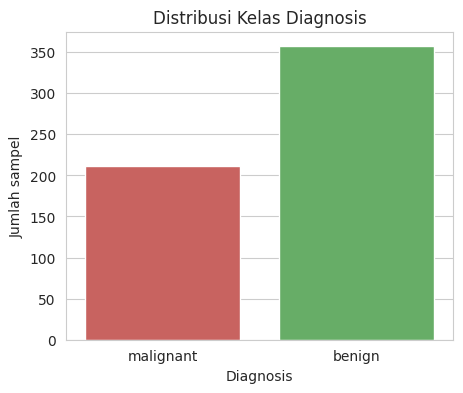

In [ ]:
# Distribusi kelas: apakah data seimbang atau tidak?
print(df["diagnosis"].value_counts())
print()
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=["#d9534f", "#5cb85c"], legend=False)
plt.title("Distribusi Kelas Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Jumlah sampel")
plt.show()

**Interpretasi:** data memiliki dua kelas dengan jumlah yang tidak sama persis (jinak lebih banyak dari ganas), tetapi perbandingannya masih wajar. Karena itu, saat membagi data digunakan *stratified split* agar proporsi kelas tetap terjaga di data latih dan data uji.

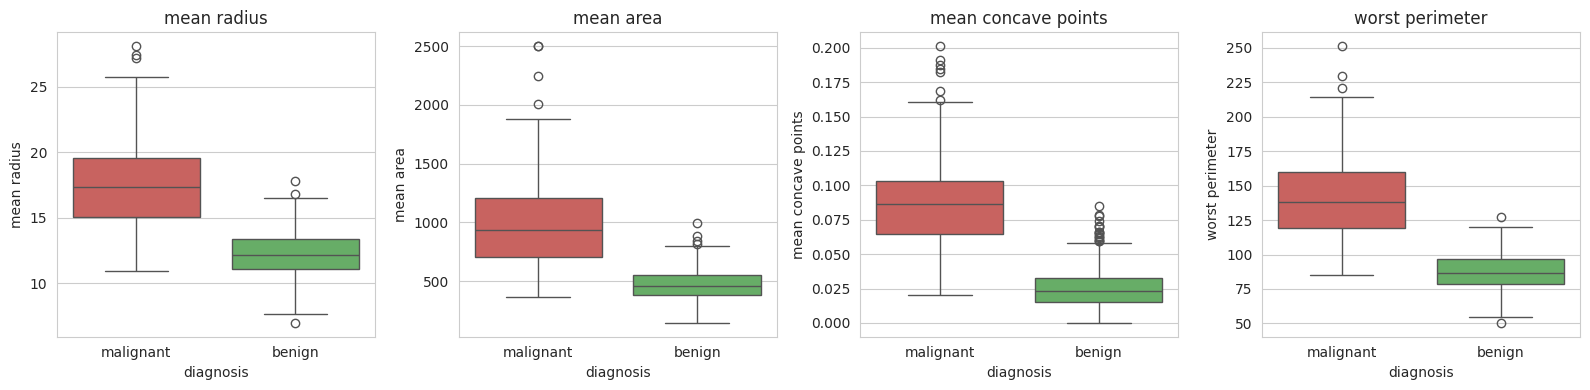

In [ ]:
# Perbandingan beberapa fitur utama antara tumor jinak dan ganas
fitur_utama = ["mean radius", "mean area", "mean concave points", "worst perimeter"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, fitur_utama):
    sns.boxplot(data=df, x="diagnosis", y=f, hue="diagnosis",
                palette=["#d9534f", "#5cb85c"], legend=False, ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.show()

**Interpretasi:** pada keempat fitur, tumor *ganas* cenderung memiliki nilai yang lebih besar dibanding tumor *jinak*. Ini menunjukkan bahwa fitur-fitur tersebut memang informatif untuk membedakan kedua kelas.

### 4.4 Pembagian Data Latih dan Data Uji

In [ ]:
# Memisahkan fitur (X) dan target (y)
X = data.data
y = data.target   # 0 = malignant, 1 = benign

# 80% data latih, 20% data uji; stratify=y menjaga proporsi kelas tetap sama
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (455, 30)
Data uji  : (114, 30)


### 4.5 Preprocessing dan Pemodelan

Fitur pada dataset ini memiliki skala yang sangat berbeda (misalnya `area` bernilai ratusan, sedangkan `smoothness` bernilai di bawah 1). Algoritma berbasis jarak/gradien seperti KNN, SVM, dan Logistic Regression sensitif terhadap hal ini, sehingga dilakukan **standardisasi** (`StandardScaler`).

Standardisasi dimasukkan ke dalam `Pipeline` supaya *scaler* hanya "belajar" dari data latih (tanpa *data leakage* dari data uji). Decision Tree dan Random Forest tidak memerlukan standardisasi.

In [ ]:
# Mendefinisikan lima model; model yang sensitif skala dibungkus pipeline + StandardScaler
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "SVM":                 make_pipeline(StandardScaler(), SVC(random_state=42)),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
}

# Validasi silang 5-fold pada data latih untuk menilai kestabilan tiap model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_cv = {}
for nama, model in models.items():
    skor = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    hasil_cv[nama] = skor.mean()
    print(f"{nama:<20} | Akurasi CV rata-rata: {skor.mean():.4f}  (+/- {skor.std():.4f})")

Logistic Regression  | Akurasi CV rata-rata: 0.9780  (+/- 0.0098)
KNN                  | Akurasi CV rata-rata: 0.9626  (+/- 0.0112)
SVM                  | Akurasi CV rata-rata: 0.9692  (+/- 0.0146)
Decision Tree        | Akurasi CV rata-rata: 0.9165  (+/- 0.0179)
Random Forest        | Akurasi CV rata-rata: 0.9626  (+/- 0.0179)


### 4.6 Evaluasi pada Data Uji

In [ ]:
# Melatih tiap model pada seluruh data latih, lalu menguji pada data uji
rows = []
prediksi = {}
for nama, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    prediksi[nama] = y_pred
    rows.append({
        "Model": nama,
        "Akurasi CV": hasil_cv[nama],
        "Akurasi Uji": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    })

hasil = pd.DataFrame(rows).set_index("Model").round(4).sort_values("Akurasi CV", ascending=False)
hasil

,Akurasi CV,Akurasi Uji,Precision,Recall,F1-score
Model,,,,,
Logistic Regression,0.9780,0.9825,0.9861,0.9861,0.9861
SVM,0.9692,0.9825,0.9861,0.9861,0.9861
KNN,0.9626,0.9561,0.9589,0.9722,0.9655
Random Forest,0.9626,0.9561,0.9589,0.9722,0.9655
Decision Tree,0.9165,0.9123,0.9559,0.9028,0.9286


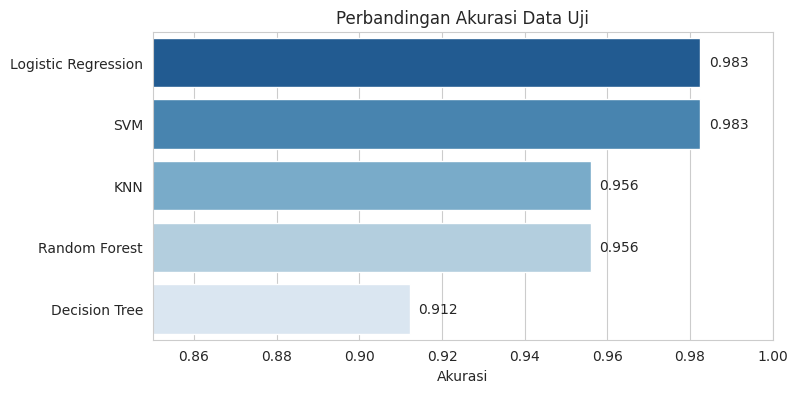

In [ ]:
# Visualisasi perbandingan akurasi uji antar model
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=hasil["Akurasi Uji"], y=hasil.index, hue=hasil.index, palette="Blues_r", legend=False)
plt.xlim(0.85, 1.0)
plt.title("Perbandingan Akurasi Data Uji")
plt.xlabel("Akurasi")
plt.ylabel("")
for p in ax.patches:
    ax.text(p.get_width() + 0.002, p.get_y() + p.get_height() / 2, f"{p.get_width():.3f}", va="center")
plt.show()

### 4.7 Evaluasi Model Terbaik

In [ ]:
# Memilih model terbaik berdasarkan akurasi validasi silang (lebih adil daripada satu kali uji)
model_terbaik = hasil.index[0]
y_pred_terbaik = prediksi[model_terbaik]
print("Model terbaik:", model_terbaik)
print()
print(classification_report(y_test, y_pred_terbaik, target_names=data.target_names))

Model terbaik: Logistic Regression

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



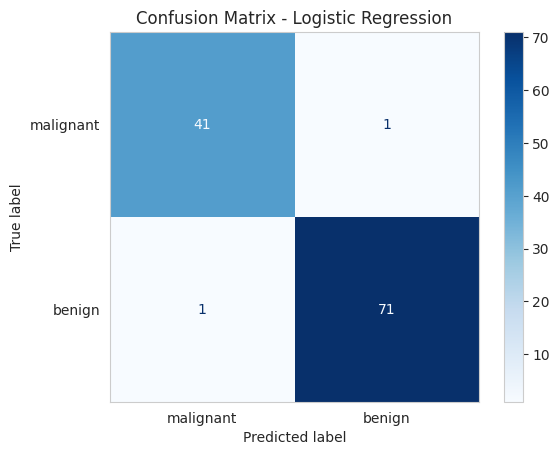

Ganas terdeteksi benar (True Negative) : 41
Jinak salah dikira ganas (False Positive): 1
GANAS SALAH DIKIRA JINAK (False Negative): 1   <- kesalahan paling berbahaya
Jinak terdeteksi benar (True Positive) : 71


In [ ]:
# Confusion matrix: membandingkan label asli dengan prediksi model
cm = confusion_matrix(y_test, y_pred_terbaik)
disp = ConfusionMatrixDisplay(cm, display_labels=data.target_names)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {model_terbaik}")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Ganas terdeteksi benar (True Negative) : {tn}")
print(f"Jinak salah dikira ganas (False Positive): {fp}")
print(f"GANAS SALAH DIKIRA JINAK (False Negative): {fn}   <- kesalahan paling berbahaya")
print(f"Jinak terdeteksi benar (True Positive) : {tp}")

**Cara membaca confusion matrix:** baris menunjukkan label sebenarnya, kolom menunjukkan prediksi model. Angka di diagonal utama adalah prediksi yang benar. Pada kasus ini, *false negative* (tumor ganas yang diprediksi jinak) adalah kesalahan yang paling berisiko karena pasien bisa terlambat ditangani.

### 4.8 Fitur yang Paling Berpengaruh

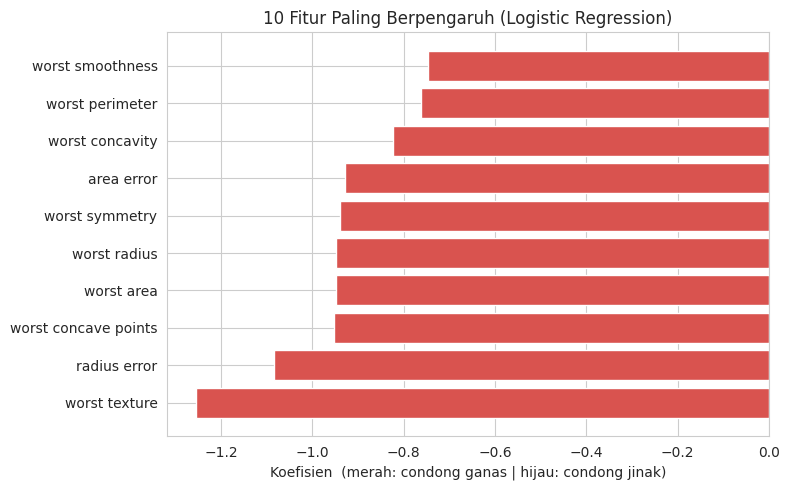

In [ ]:
# Mengambil koefisien Logistic Regression (pada data yang sudah distandarisasi)
# Koefisien negatif -> cenderung ke kelas 0 (ganas); positif -> cenderung ke kelas 1 (jinak)
lr = models["Logistic Regression"]
koef = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=data.feature_names)
top = koef.reindex(koef.abs().sort_values(ascending=False).head(10).index).sort_values()

plt.figure(figsize=(8, 5))
warna = ["#d9534f" if v < 0 else "#5cb85c" for v in top.values]
plt.barh(top.index, top.values, color=warna)
plt.title("10 Fitur Paling Berpengaruh (Logistic Regression)")
plt.xlabel("Koefisien  (merah: condong ganas | hijau: condong jinak)")
plt.tight_layout()
plt.show()

## 5. Hasil dan Pembahasan

In [ ]:
# Ringkasan hasil otomatis dari model terbaik
r = hasil.loc[model_terbaik]
print(f"Model terbaik (berdasarkan akurasi CV) : {model_terbaik}")
print(f"Akurasi validasi silang                : {r['Akurasi CV']*100:.2f}%")
print(f"Akurasi pada data uji                  : {r['Akurasi Uji']*100:.2f}%")
print(f"Precision / Recall / F1 (kelas jinak)  : {r['Precision']:.3f} / {r['Recall']:.3f} / {r['F1-score']:.3f}")
print(f"Jumlah ganas salah dikira jinak (FN)   : {fn} dari {fn + tn} kasus ganas pada data uji")

Model terbaik (berdasarkan akurasi CV) : Logistic Regression
Akurasi validasi silang                : 97.80%
Akurasi pada data uji                  : 98.25%
Precision / Recall / F1 (kelas jinak)  : 0.986 / 0.986 / 0.986
Jumlah ganas salah dikira jinak (FN)   : 1 dari 42 kasus ganas pada data uji


**Pembahasan:**

1. Seluruh model mampu mengklasifikasikan tumor dengan akurasi tinggi (di atas 90%), yang menunjukkan bahwa 30 fitur inti sel memang sangat informatif.
2. **Logistic Regression** dan **SVM** (yang didahului standardisasi) menunjukkan performa terbaik dan paling stabil, dengan akurasi sekitar 98% pada data uji. Hal ini menunjukkan bahwa batas antara kelas jinak dan ganas pada dataset ini cukup mudah dipisahkan secara linear setelah fitur distandarisasi.
3. **Decision Tree tunggal** memiliki performa terendah karena cenderung *overfitting*; **Random Forest** memperbaikinya dengan menggabungkan banyak pohon.
4. Dari sisi medis, jumlah *false negative* (ganas dikira jinak) yang sangat kecil adalah hasil yang diharapkan, namun tetap perlu diingat bahwa model ini hanyalah alat bantu, bukan pengganti diagnosis dokter.
5. Fitur yang paling berpengaruh umumnya berkaitan dengan ukuran dan bentuk tidak beraturan inti sel pada nilai *worst* (misalnya `worst radius`, `worst texture`, `worst concave points`), sejalan dengan pengetahuan bahwa sel ganas cenderung lebih besar dan bentuknya tidak teratur.

**Keterbatasan:** data hanya 569 sampel dari satu sumber, dibagi dengan satu kali *split* sehingga hasil bisa sedikit berubah jika `random_state` diubah; model belum divalidasi pada data rumah sakit lain.

## 6. Manfaat Penerapan

- **Membantu deteksi dini:** model dapat menjadi *second opinion* otomatis yang cepat bagi tenaga medis.
- **Mengurangi subjektivitas:** keputusan didasarkan pada pengukuran kuantitatif, bukan hanya penilaian visual.
- **Efisiensi waktu dan biaya:** prediksi dihasilkan dalam hitungan detik, membantu prioritas penanganan pasien yang berisiko ganas.
- **Dapat diterapkan di fasilitas dengan keterbatasan tenaga ahli:** model dapat membantu penyaringan awal di daerah yang kekurangan patolog.
- **Dapat dijelaskan:** karena memakai Logistic Regression, fitur yang berpengaruh dapat diinterpretasikan oleh dokter, bukan sekadar "kotak hitam".

## 7. Kesimpulan

Permasalahan klasifikasi tumor payudara (jinak vs ganas) dapat diselesaikan dengan baik menggunakan *machine learning* berbasis ciri inti sel hasil FNA. Setelah dilakukan standardisasi fitur, model sederhana seperti Logistic Regression mampu mencapai akurasi sekitar 98% pada data uji dengan jumlah kesalahan yang sangat kecil. Meskipun demikian, model ini ditujukan sebagai **alat bantu keputusan**, bukan pengganti diagnosis profesional.

## 8. Referensi

1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
2. Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, 1905, 861–870.
3. Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1994). Machine learning techniques to diagnose breast cancer from fine-needle aspirates. *Cancer Letters*, 77, 163–171.
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
5. Dokumentasi scikit-learn: *Breast cancer wisconsin (diagnostic) dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html